# Pulse of Prevention: Analyzing Heart Health for Better Outcomes
**HealthPulse Analytics | Exploratory Data Analysis (EDA)**

**Goal:** find the key factors linked to heart disease, build a profile of high-risk patients, and suggest preventive actions.

**Notebook map**
1. Setup
2. Load and first look
3. Data cleaning and preprocessing (missing values, data types, duplicates, outliers, normalization)
4. Basic questions (10)
5. Medium questions (10)
6. Advanced questions (5)
7. High-risk patient profile
8. Recommendations, further research, limitations

> This is a practice project. Nothing here is medical advice.

## 1. Setup

In [1]:
import warnings
warnings.filterwarnings("ignore")
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, roc_curve, confusion_matrix)
from sklearn.model_selection import train_test_split, RepeatedStratifiedKFold, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# ---- project settings --------------------------------------------------
DATA_PATH = Path("../data/heart.csv")
FIG_DIR = Path("../outputs/figures")
FIG_DIR.mkdir(parents=True, exist_ok=True)

DROP_DUPLICATES = True   # the file has 723 repeated rows (see section 3.3)
FLIP_TARGET = True       # data suggests target is reversed vs the dictionary (see section 3.4)
RANDOM_STATE = 42

# ---- plot style: two colours used everywhere (blue = no disease, orange = disease)
BLUE, ORANGE, GREY = "#2a78d6", "#eb6834", "#8a8a85"
PAL = {"No disease": BLUE, "Disease": ORANGE}
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False,
                     "figure.dpi": 100, "axes.titleweight": "bold", "axes.grid.axis": "y"})
BLUES4 = ["#b7d3f6", "#6da7ec", "#2a78d6", "#0d366b"]

def save(name):
    plt.tight_layout()
    plt.savefig(FIG_DIR / f"{name}.png", dpi=150, bbox_inches="tight")
    plt.show()

## 2. Load and first look

In [2]:
raw = pd.read_csv(DATA_PATH)
print("Shape:", raw.shape)
raw.head()

Shape: (1025, 14)


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,52,1,0,125,212,0,1,168,0,1.0,2,2,3,0
1,53,1,0,140,203,1,0,155,1,3.1,0,0,3,0
2,70,1,0,145,174,0,1,125,1,2.6,0,0,3,0
3,61,1,0,148,203,0,1,161,0,0.0,2,1,3,0
4,62,0,0,138,294,1,1,106,0,1.9,1,3,2,0


In [3]:
raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 1025 entries, 0 to 1024
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1025 non-null   int64  
 1   sex       1025 non-null   int64  
 2   cp        1025 non-null   int64  
 3   trestbps  1025 non-null   int64  
 4   chol      1025 non-null   int64  
 5   fbs       1025 non-null   int64  
 6   restecg   1025 non-null   int64  
 7   thalach   1025 non-null   int64  
 8   exang     1025 non-null   int64  
 9   oldpeak   1025 non-null   float64
 10  slope     1025 non-null   int64  
 11  ca        1025 non-null   int64  
 12  thal      1025 non-null   int64  
 13  target    1025 non-null   int64  
dtypes: float64(1), int64(13)
memory usage: 112.2 KB


In [4]:
raw.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
age,1025.0,54.43,9.07,29.0,48.0,56.0,61.0,77.0
sex,1025.0,0.70,0.46,0.0,0.0,1.0,1.0,1.0
cp,1025.0,0.94,1.03,0.0,0.0,1.0,2.0,3.0
trestbps,1025.0,131.61,17.52,94.0,120.0,130.0,140.0,200.0
chol,1025.0,246.00,51.59,126.0,211.0,240.0,275.0,564.0
fbs,1025.0,0.15,0.36,0.0,0.0,0.0,0.0,1.0
restecg,1025.0,0.53,0.53,0.0,0.0,1.0,1.0,2.0
thalach,1025.0,149.11,23.01,71.0,132.0,152.0,166.0,202.0
exang,1025.0,0.34,0.47,0.0,0.0,0.0,1.0,1.0
oldpeak,1025.0,1.07,1.18,0.0,0.0,0.8,1.8,6.2


**Quick read:** 1,025 rows, 14 numeric columns, no blanks. The columns are a mix of true measurements (`age`, `trestbps`, `chol`, `thalach`, `oldpeak`) and coded categories (`sex`, `cp`, `fbs`, `restecg`, `exang`, `slope`, `ca`, `thal`, `target`). We will treat them differently later.

## 3. Data cleaning and preprocessing

The brief asks for four things: missing values, data types, outliers, normalization. While checking, two more issues showed up (duplicates and a possibly reversed target), so they are handled here too.

### 3.1 Missing values

In [5]:
print("Blank cells in raw file:", raw.isna().sum().sum())

# Blanks can hide as invalid codes. Compare each coded column with the data dictionary.
valid_codes = {"sex": [0, 1], "cp": [0, 1, 2, 3], "fbs": [0, 1], "restecg": [0, 1, 2],
               "exang": [0, 1], "slope": [0, 1, 2], "ca": [0, 1, 2, 3], "thal": [1, 2, 3], "target": [0, 1]}
rows = []
for col, ok in valid_codes.items():
    bad = raw.loc[~raw[col].isin(ok), col]
    if len(bad):
        rows.append({"column": col, "invalid values": sorted(bad.unique()), "rows affected": len(bad)})
pd.DataFrame(rows)

Blank cells in raw file: 0


,column,invalid values,rows affected
0,ca,[4],18
1,thal,[0],7


No blank cells, but `ca` has the value 4 and `thal` has the value 0. Neither exists in the data dictionary (`ca` is 0-3, `thal` is 1-3). In the original heart data these are placeholders for missing values, so we will treat them as **missing** and fill them with the most common value (mode). It is only a handful of rows, so the choice hardly matters. It is applied in 3.3 after duplicates are removed.

### 3.2 Data types

In [6]:
NUM = ["age", "trestbps", "chol", "thalach", "oldpeak"]               # real measurements
CAT = ["sex", "cp", "fbs", "restecg", "exang", "slope", "ca", "thal"]  # coded categories

print("Numeric measurements:", NUM)
print("Coded categories    :", CAT)
print()
print(raw.dtypes.to_string())

Numeric measurements: ['age', 'trestbps', 'chol', 'thalach', 'oldpeak']
Coded categories    : ['sex', 'cp', 'fbs', 'restecg', 'exang', 'slope', 'ca', 'thal']

age           int64
sex           int64
cp            int64
trestbps      int64
chol          int64
fbs           int64
restecg       int64
thalach       int64
exang         int64
oldpeak     float64
slope         int64
ca            int64
thal          int64
target        int64


All columns are already numeric, so nothing needs parsing. Two follow-ups: (a) `ca` and `thal` become whole numbers again after the missing-value fill, and (b) for plotting we add readable label columns (`status`, `sex_label`). The coded columns stay numeric so correlations and the model still work.

### 3.3 Duplicates, invalid codes

In [7]:
n_dup = raw.duplicated().sum()
print(f"Exact duplicate rows: {n_dup} of {len(raw)} ({n_dup/len(raw):.0%})")
print(f"Unique patients     : {len(raw) - n_dup}")

Exact duplicate rows: 723 of 1025 (71%)
Unique patients     : 302


About 70% of the file is repeated rows. All 14 values match exactly, which is very unlikely for different patients, so these look like copy-paste duplicates. Keeping them would overweight a few patients and make every test look more certain than it is. Later we also see that they inflate model accuracy. **Default: drop duplicates** (set `DROP_DUPLICATES = False` in section 1 to see the effect).

In [8]:
df = raw.drop_duplicates().reset_index(drop=True) if DROP_DUPLICATES else raw.copy()

# invalid codes -> missing -> mode
df.loc[df["ca"] == 4, "ca"] = np.nan
df.loc[df["thal"] == 0, "thal"] = np.nan
print("Missing after flagging invalid codes:\n", df[["ca", "thal"]].isna().sum().to_string())

for col in ["ca", "thal"]:
    df[col] = df[col].fillna(df[col].mode()[0]).astype(int)

print("\nRows used for analysis:", len(df))

Missing after flagging invalid codes:
 ca      4
thal    2

Rows used for analysis: 302


In [9]:
# How much did removing duplicates change the headline numbers?
compare = pd.DataFrame({
    "raw file (with duplicates)": [len(raw), raw.age.mean(), (raw.sex == 1).mean() * 100, raw.chol.mean(), raw.trestbps.mean(), raw.fbs.sum()],
    "cleaned": [len(df), df.age.mean(), (df.sex == 1).mean() * 100, df.chol.mean(), df.trestbps.mean(), df.fbs.sum()],
}, index=["patients", "avg age", "% male", "avg cholesterol", "avg resting BP", "high fasting sugar (count)"]).round(1)
compare

,raw file (with duplicates),cleaned
patients,1025.0,302.0
avg age,54.4,54.4
% male,69.6,68.2
avg cholesterol,246.0,246.5
avg resting BP,131.6,131.6
high fasting sugar (count),153.0,45.0


### 3.4 Check the target column

The dictionary says `target = 1` means heart disease. Before trusting that, test it. If `target = 1` really means disease, those patients should show *more* exercise angina, *more* ST depression (`oldpeak`), *more* blocked vessels (`ca`), *lower* peak heart rate (`thalach`), and be older and more often male.

In [10]:
check = df.groupby("target")[["age", "sex", "exang", "oldpeak", "ca", "thalach"]].mean().round(2)
display(check)

expect_higher = ["age", "sex", "exang", "oldpeak", "ca"]
expect_lower = ["thalach"]
agree = sum(check.loc[1, c] > check.loc[0, c] for c in expect_higher) + \
        sum(check.loc[1, c] < check.loc[0, c] for c in expect_lower)
print(f"{agree} of 6 markers behave the way 'target = 1 means disease' predicts")

,age,sex,exang,oldpeak,ca,thalach
target,,,,,,
0,56.60,0.83,0.55,1.59,1.14,139.10
1,52.59,0.56,0.14,0.59,0.27,158.38


0 of 6 markers behave the way 'target = 1 means disease' predicts


**Result: 0 of 6.** Every marker points the opposite way, so in this file `target = 1` behaves like *no disease* and `target = 0` like *disease*. This matches what others have reported about this Kaggle version of the data. Without a fix, the analysis would say that exercise angina and blocked vessels *protect* against heart disease, which is clinically backwards.

**Decision:** create a new column `disease` (1 = disease) that reverses `target`, and use it everywhere. If you disagree, set `FLIP_TARGET = False` in section 1 and re-run; everything updates.

In [11]:
df["disease"] = 1 - df["target"] if FLIP_TARGET else df["target"]
raw["disease"] = 1 - raw["target"] if FLIP_TARGET else raw["target"]

df["status"] = df["disease"].map({0: "No disease", 1: "Disease"})
df["sex_label"] = df["sex"].map({0: "Female", 1: "Male"})
STATUS_ORDER = ["No disease", "Disease"]

# same 6 markers again, now using 'disease'
recheck = df.groupby("disease")[["age", "sex", "exang", "oldpeak", "ca", "thalach"]].mean().round(2)
display(recheck)
print(f"Disease prevalence in cleaned data: {df.disease.mean():.1%}  ({df.disease.sum()} of {len(df)} patients)")

,age,sex,exang,oldpeak,ca,thalach
disease,,,,,,
0,52.59,0.56,0.14,0.59,0.27,158.38
1,56.60,0.83,0.55,1.59,1.14,139.10


Disease prevalence in cleaned data: 45.7%  (138 of 302 patients)


### 3.5 Outliers

In [12]:
def iqr_bounds(s):
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    return q1 - 1.5 * iqr, q3 + 1.5 * iqr

rows = []
for c in NUM:
    lo, hi = iqr_bounds(df[c])
    n_out = ((df[c] < lo) | (df[c] > hi)).sum()
    rows.append({"column": c, "lower fence": round(lo, 1), "upper fence": round(hi, 1),
                 "min": df[c].min(), "max": df[c].max(), "outliers": n_out})
outlier_table = pd.DataFrame(rows)
outlier_table

,column,lower fence,upper fence,min,max,outliers
0,age,28.5,80.5,29.0,77.0,0
1,trestbps,90.0,170.0,94.0,200.0,9
2,chol,115.4,370.4,126.0,564.0,5
3,thalach,84.1,215.1,71.0,202.0,1
4,oldpeak,-2.4,4.0,0.0,6.2,5


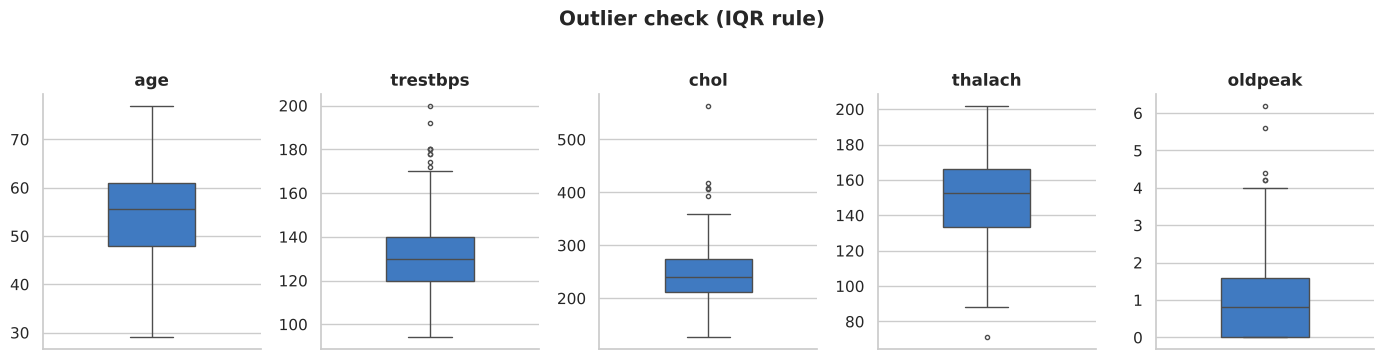

In [13]:
fig, axes = plt.subplots(1, 5, figsize=(14, 3.5))
for ax, c in zip(axes, NUM):
    sns.boxplot(y=df[c], ax=ax, color=BLUE, width=0.4, fliersize=3)
    ax.set_title(c); ax.set_ylabel("")
fig.suptitle("Outlier check (IQR rule)", y=1.02, fontweight="bold")
save("01_outlier_boxplots")

**What we do:** the flagged values (for example cholesterol of 564 or resting BP of 200) are medically possible, not typing errors. So:
- the descriptive questions use the data **as is**, so the numbers reflect real patients;
- a **capped copy** (values pulled in to the IQR fences) is used for normalization and the model, so a few extreme values don't dominate.

In [14]:
df_capped = df.copy()
for c in NUM:
    lo, hi = iqr_bounds(df[c])
    df_capped[c] = df[c].clip(lo, hi)
print("Values changed by capping:", int((df_capped[NUM] != df[NUM]).sum().sum()))

Values changed by capping: 20


### 3.6 Normalization

In [15]:
# z-score (mean 0, spread 1) so measurements in different units can be compared side by side
df_scaled = df_capped.copy()
df_scaled[NUM] = StandardScaler().fit_transform(df_capped[NUM])
df_scaled[NUM].describe().loc[["mean", "std"]].round(2)

,age,trestbps,chol,thalach,oldpeak
mean,-0.0,0.0,-0.0,-0.0,0.0
std,1.0,1.0,1.0,1.0,1.0


`df_scaled` is used for the side-by-side comparison in Medium Q10. The logistic regression (Advanced Q3) does its own scaling inside a pipeline, fitted on training data only, to avoid leaking test information.

**Cleaned data is ready:** `df` (analysis), `df_capped` (modeling), `df_scaled` (comparison).

### 3.7 Overview: how each variable relates to disease

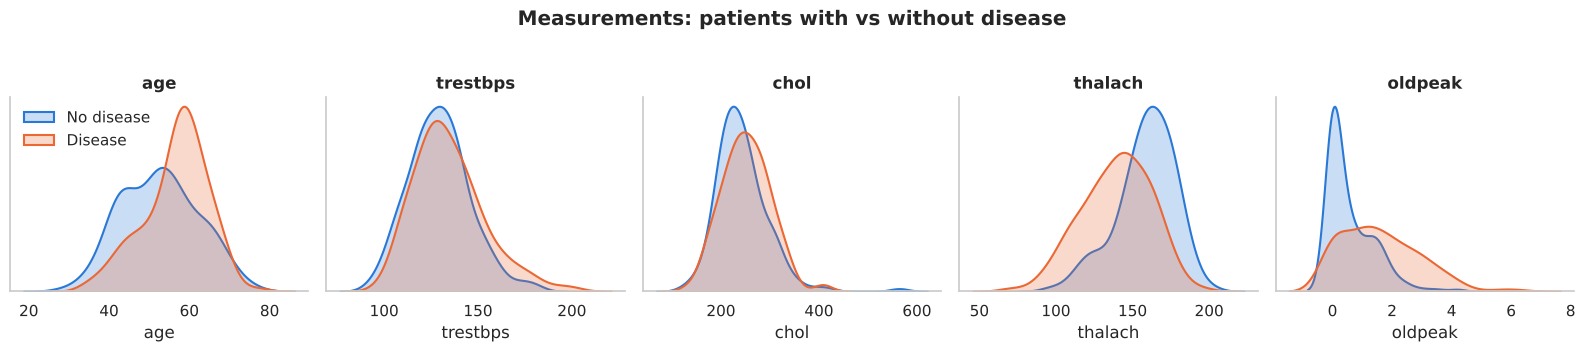

In [16]:
fig, axes = plt.subplots(1, 5, figsize=(16, 3.4))
for ax, c in zip(axes, NUM):
    for s in STATUS_ORDER:
        sns.kdeplot(df.loc[df.status == s, c], ax=ax, color=PAL[s], fill=True, alpha=0.25, label=s, linewidth=1.5)
    ax.set_title(c); ax.set_ylabel(""); ax.set_yticks([])
axes[0].legend(frameon=False)
fig.suptitle("Measurements: patients with vs without disease", y=1.03, fontweight="bold")
save("02_numeric_distributions")

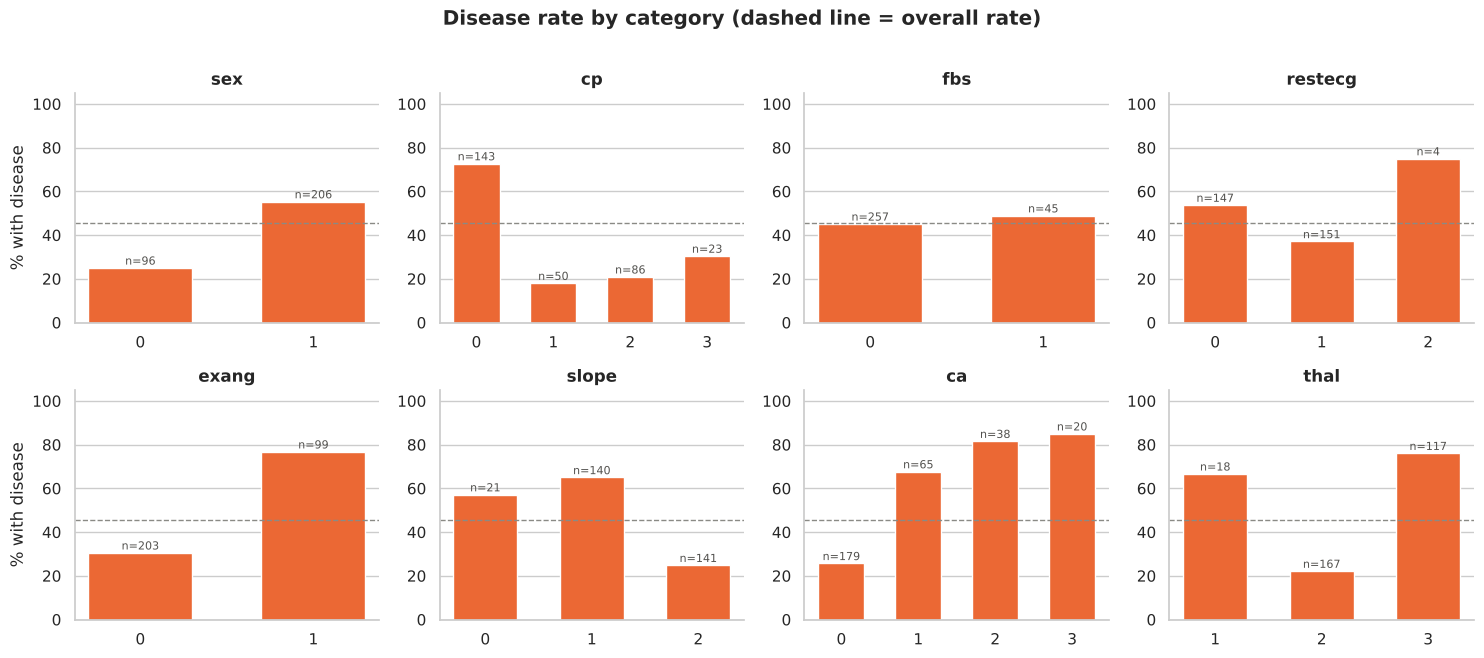

In [17]:
fig, axes = plt.subplots(2, 4, figsize=(15, 6.5))
for ax, c in zip(axes.ravel(), CAT):
    r = df.groupby(c)["disease"].mean() * 100
    n = df.groupby(c).size()
    ax.bar(r.index.astype(str), r.values, color=ORANGE, width=0.6)
    ax.axhline(df.disease.mean() * 100, color=GREY, ls="--", lw=1)
    for x, (v, k) in enumerate(zip(r.values, n.values)):
        ax.text(x, v + 1.5, f"n={k}", ha="center", fontsize=8, color="#52514e")
    ax.set_title(c); ax.set_ylim(0, 105); ax.set_xlabel("")
axes[0, 0].set_ylabel("% with disease"); axes[1, 0].set_ylabel("% with disease")
fig.suptitle("Disease rate by category (dashed line = overall rate)", y=1.01, fontweight="bold")
save("03_disease_rate_by_category")

These two charts are the whole project in one view. Later sections test each pattern properly.

In [18]:
# small helpers used in the questions below
def rate_table(col, data=None):
    d = df if data is None else data
    t = d.groupby(col)["disease"].agg(patients="size", with_disease="sum", rate="mean")
    t["rate"] = (t["rate"] * 100).round(1).astype(str) + "%"
    return t

def chi2_p(col, data=None):
    d = df if data is None else data
    return stats.chi2_contingency(pd.crosstab(d[col], d["disease"]))[1]

def stacked(col, ax, pct=False, data=None):
    d = df if data is None else data
    ct = pd.crosstab(d[col], d["status"])[STATUS_ORDER]
    if pct:
        ct = ct.div(ct.sum(axis=1), axis=0) * 100
    ct.plot(kind="bar", stacked=True, color=[BLUE, ORANGE], ax=ax, width=0.7, edgecolor="white")
    ax.set_xlabel(col); ax.set_ylabel("% of group" if pct else "patients"); ax.tick_params(axis="x", rotation=0)
    ax.legend(frameon=False, title="", loc="upper left", bbox_to_anchor=(1, 1))

def cohens_d(a, b):
    sp = np.sqrt(((len(a) - 1) * a.var() + (len(b) - 1) * b.var()) / (len(a) + len(b) - 2))
    return (a.mean() - b.mean()) / sp

def p_text(p):
    return "p < 0.001" if p < 0.001 else f"p = {p:.3f}"

## 4. Basic questions

### B1. What is the average age of patients?
*Hint: `data['age'].mean()`. Why it matters: shows which age group to target with prevention programs.*

Average age: 54.4 years (median 56; range 29-77)

Average age by status:
status
Disease       56.6
No disease    52.6


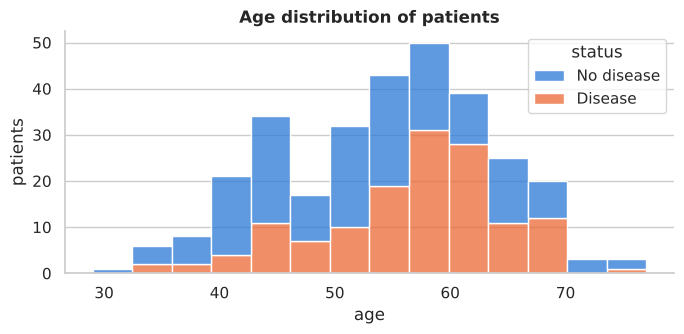

In [19]:
print(f"Average age: {df.age.mean():.1f} years (median {df.age.median():.0f}; range {df.age.min()}-{df.age.max()})")
print("\nAverage age by status:")
print(df.groupby("status")["age"].mean().round(1).to_string())

fig, ax = plt.subplots(figsize=(7, 3.5))
sns.histplot(data=df, x="age", hue="status", hue_order=STATUS_ORDER, palette=PAL, bins=14, multiple="stack", ax=ax, edgecolor="white")
ax.set_title("Age distribution of patients"); ax.set_ylabel("patients")
save("04_b1_age_distribution")

### B2. What is the gender distribution?
*Hint: `data['sex'].value_counts()`. Why it matters: shows whether prevention needs to be gender-specific.*

In [20]:
g = df["sex_label"].value_counts()
print((g.to_frame("patients").assign(share=(g / len(df) * 100).round(1).astype(str) + "%")).to_string())
print("\nDisease rate by sex:")
display(rate_table("sex_label"))
print(f"Chi-square test, sex vs disease: {p_text(chi2_p('sex'))}")

           patients  share
sex_label                 
Male            206  68.2%
Female           96  31.8%

Disease rate by sex:


,patients,with_disease,rate
sex_label,,,
Female,96,24,25.0%
Male,206,114,55.3%


Chi-square test, sex vs disease: p < 0.001


### B3. What is the average resting blood pressure?
*Hint: `data['trestbps'].mean()`. Why it matters: a baseline for spotting high-BP patients early.*

In [21]:
bp = df.trestbps
print(f"Average resting BP: {bp.mean():.1f} mm Hg (median {bp.median():.0f})")
print(f"Patients at or above 140 mm Hg (commonly used 'high' threshold): {(bp >= 140).sum()} ({(bp >= 140).mean():.0%})")

Average resting BP: 131.6 mm Hg (median 130)
Patients at or above 140 mm Hg (commonly used 'high' threshold): 97 (32%)


### B4. How many patients have fasting blood sugar above 120 mg/dl?
*Hint: `data['fbs'].sum()`. Why it matters: high blood sugar is a known risk factor, so these patients can get diet and lifestyle advice early.*

In [22]:
print(f"Patients with fasting blood sugar > 120: {df.fbs.sum()} of {len(df)} ({df.fbs.mean():.1%})")

Patients with fasting blood sugar > 120: 45 of 302 (14.9%)


### B5. What types of chest pain are recorded?
*Hint: `data['cp'].unique()`. Why it matters: different pain types signal different severity, which helps with triage.*

In [23]:
print("Chest pain codes:", [int(x) for x in sorted(df.cp.unique())])
display(rate_table("cp"))

Chest pain codes: [0, 1, 2, 3]


,patients,with_disease,rate
cp,,,
0,143,104,72.7%
1,50,9,18.0%
2,86,18,20.9%
3,23,7,30.4%


The brief gives no names for the four codes, so we keep them as codes 0-3.

### B6. What is the maximum heart rate achieved?
*Hint: `data['thalach'].max()`. Why it matters: helps set safe limits for exercise programs.*

In [24]:
hr = df.thalach
top = df.loc[hr.idxmax()]
print(f"Highest max heart rate recorded: {hr.max()} bpm (age {top.age}, {top.status.lower()})")
print(f"Lowest: {hr.min()} bpm | Average: {hr.mean():.1f} bpm")

Highest max heart rate recorded: 202 bpm (age 29, no disease)
Lowest: 71 bpm | Average: 149.6 bpm


### B7. What percentage of patients have exercise-induced angina?
*Hint: `data['exang'].mean() * 100`. Why it matters: shows exercise tolerance, so exercise plans can be tailored.*

In [25]:
print(f"Exercise-induced angina: {df.exang.mean() * 100:.1f}% of patients ({df.exang.sum()} of {len(df)})")

Exercise-induced angina: 32.8% of patients (99 of 302)


### B8. What is the average cholesterol level?
*Hint: `data['chol'].mean()`. Why it matters: cholesterol is a key indicator for diet and medication plans.*

In [26]:
c = df.chol
print(f"Average cholesterol: {c.mean():.1f} mg/dl (median {c.median():.0f})")
print(f"Patients at or above 240 mg/dl (commonly used 'high' threshold): {(c >= 240).sum()} ({(c >= 240).mean():.0%})")

Average cholesterol: 246.5 mg/dl (median 240)
Patients at or above 240 mg/dl (commonly used 'high' threshold): 155 (51%)


### B9. How many patients have resting ECG result 2?
*Hint: `data['restecg'].value_counts()[2]`. Why it matters: ECG results help with early diagnosis.*

In [27]:
vc = df.restecg.value_counts().sort_index()
print(vc.to_string())
print(f"\nPatients with restecg = 2: {vc.get(2, 0)}")

restecg
0    147
1    151
2      4

Patients with restecg = 2: 4


Only a tiny group, so any pattern for `restecg = 2` should be read with caution.

### B10. What is the distribution of major vessels colored by fluoroscopy (`ca`)?
*Hint: `data['ca'].value_counts()`. Why it matters: more affected vessels mean more severe disease, which guides who needs urgent care.*

In [28]:
vc = df.ca.value_counts().sort_index()
print(pd.DataFrame({"patients": vc, "share": (vc / len(df) * 100).round(1).astype(str) + "%"}).to_string())

    patients  share
ca                 
0        179  59.3%
1         65  21.5%
2         38  12.6%
3         20   6.6%


## 5. Medium questions

### M1. Correlation between age and cholesterol
*Hint: `data[['age','chol']].corr()`. Why it matters: shows which ages may need more frequent cholesterol checks.*

Pearson r = 0.21 (p < 0.001) | Spearman rho = 0.19 (p < 0.001)


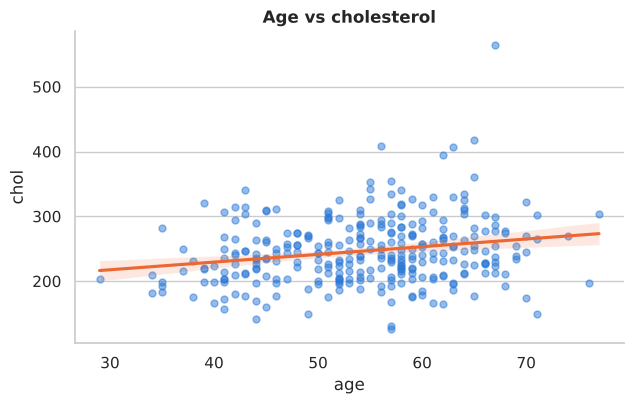

In [29]:
r, p = stats.pearsonr(df.age, df.chol)
rho, p2 = stats.spearmanr(df.age, df.chol)
print(f"Pearson r = {r:.2f} ({p_text(p)}) | Spearman rho = {rho:.2f} ({p_text(p2)})")

fig, ax = plt.subplots(figsize=(6.5, 4.2))
sns.regplot(data=df, x="age", y="chol", ax=ax, scatter_kws={"alpha": 0.5, "color": BLUE, "s": 25}, line_kws={"color": ORANGE})
ax.set_title("Age vs cholesterol")
save("05_m1_age_vs_chol")

### M2. Chest pain types across age groups
*Hint: `groupby('age')['cp'].value_counts().unstack().plot(kind='bar', stacked=True)`. Why it matters: age-specific symptom patterns help tailor diagnosis.*

cp,0,1,2,3
age_group,,,,
under 40,4,3,6,2
40-49,28,19,22,3
50-59,61,21,34,9
60+,50,7,24,9


Chi-square, age group vs chest pain type: p = 0.073


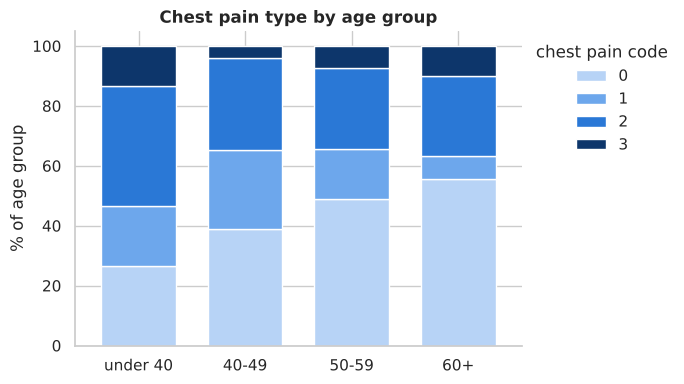

In [30]:
df["age_group"] = pd.cut(df.age, bins=[0, 39, 49, 59, 120], labels=["under 40", "40-49", "50-59", "60+"])
ct = pd.crosstab(df.age_group, df.cp)
display(ct)
print(f"Chi-square, age group vs chest pain type: {p_text(stats.chi2_contingency(ct)[1])}")

ct_pct = ct.div(ct.sum(axis=1), axis=0) * 100
ax = ct_pct.plot(kind="bar", stacked=True, figsize=(7, 4), color=BLUES4[:ct.shape[1]] if ct.shape[1] == 4 else ["#b7d3f6", "#2a78d6", "#0d366b"], edgecolor="white", width=0.7)
ax.set_ylabel("% of age group"); ax.set_xlabel(""); ax.tick_params(axis="x", rotation=0)
ax.legend(title="chest pain code", frameon=False, bbox_to_anchor=(1, 1))
ax.set_title("Chest pain type by age group")
save("06_m2_cp_by_age_group")

Age groups are used instead of single years (as in the hint) because single-year bars have only a few patients each and are unreadable.

### M3. How does max heart rate vary with exercise-induced angina?
*Hint: `groupby('exang')['thalach'].mean()`. Why it matters: guides safe exercise intensity.*

,count,mean,median
exang,,,
0,203,155.6,160.0
1,99,137.2,140.0


Welch t-test: p < 0.001 | difference = -18.4 bpm


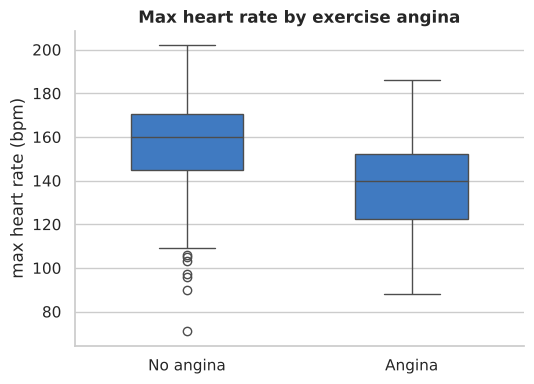

In [31]:
display(df.groupby("exang")["thalach"].agg(["count", "mean", "median"]).round(1))
a, b = df.loc[df.exang == 1, "thalach"], df.loc[df.exang == 0, "thalach"]
t, p = stats.ttest_ind(a, b, equal_var=False)
print(f"Welch t-test: {p_text(p)} | difference = {a.mean() - b.mean():.1f} bpm")

fig, ax = plt.subplots(figsize=(5.5, 4))
sns.boxplot(data=df, x="exang", y="thalach", ax=ax, color=BLUE, width=0.5)
ax.set_xticklabels(["No angina", "Angina"]); ax.set_xlabel(""); ax.set_ylabel("max heart rate (bpm)")
ax.set_title("Max heart rate by exercise angina")
save("07_m3_thalach_by_exang")

### M4. Is resting blood pressure different between men and women?
*Hint: `groupby('sex')['trestbps'].mean()` and a t-test. Why it matters: informs gender-specific advice.*

In [32]:
display(df.groupby("sex_label")["trestbps"].agg(["count", "mean", "median"]).round(1))
m, f = df.loc[df.sex == 1, "trestbps"], df.loc[df.sex == 0, "trestbps"]
t, p = stats.ttest_ind(m, f, equal_var=False)
u, p_mw = stats.mannwhitneyu(m, f)
print(f"Welch t-test: {p_text(p)} | Mann-Whitney: {p_text(p_mw)}")
print("Significant difference" if p < 0.05 else "No statistically significant difference", "(5% level)")

,count,mean,median
sex_label,,,
Female,96,133.1,131.0
Male,206,130.9,130.0


Welch t-test: p = 0.344 | Mann-Whitney: p = 0.346
No statistically significant difference (5% level)


### M5. Fasting blood sugar vs heart disease
*Hint: `pd.crosstab(data['fbs'], data['target']).plot(kind='bar', stacked=True)`. Why it matters: tells us whether blood sugar is a meaningful risk marker here.*

,patients,with_disease,rate
fbs,,,
0,257,116,45.1%
1,45,22,48.9%


Chi-square: p = 0.761


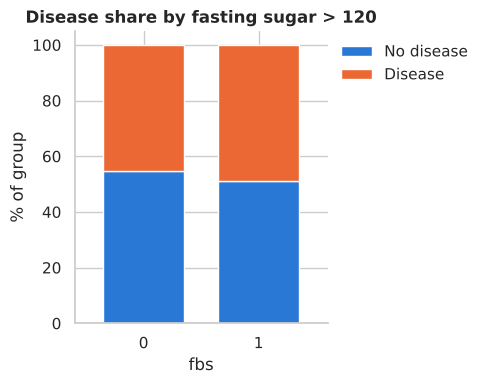

In [33]:
display(rate_table("fbs"))
print(f"Chi-square: {p_text(chi2_p('fbs'))}")
fig, ax = plt.subplots(figsize=(5, 4)); stacked("fbs", ax, pct=True)
ax.set_title("Disease share by fasting sugar > 120")
save("08_m5_fbs_vs_disease")

### M6. How does the number of major vessels (`ca`) relate to heart disease?
*Hint: `pd.crosstab(data['ca'], data['target']).plot(kind='bar', stacked=True)`. Why it matters: prioritizes patients for intensive care.*

,patients,with_disease,rate
ca,,,
0,179,46,25.7%
1,65,44,67.7%
2,38,31,81.6%
3,20,17,85.0%


Chi-square: p < 0.001


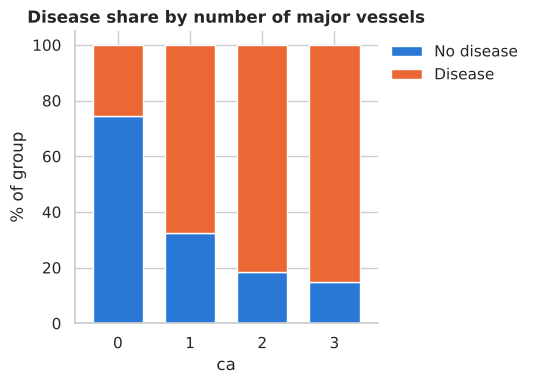

In [34]:
display(rate_table("ca"))
print(f"Chi-square: {p_text(chi2_p('ca'))}")
fig, ax = plt.subplots(figsize=(5.5, 4)); stacked("ca", ax, pct=True)
ax.set_title("Disease share by number of major vessels")
save("09_m6_ca_vs_disease")

### M7. Average `oldpeak` by chest pain type
*Hint: `groupby('cp')['oldpeak'].mean()`. Why it matters: oldpeak (ST depression) reflects how serious the heart strain is.*

,count,mean,median
cp,,,
0,143,1.38,1.2
1,50,0.32,0.0
2,86,0.81,0.5
3,23,1.39,1.2


Kruskal-Wallis across chest pain types: p < 0.001


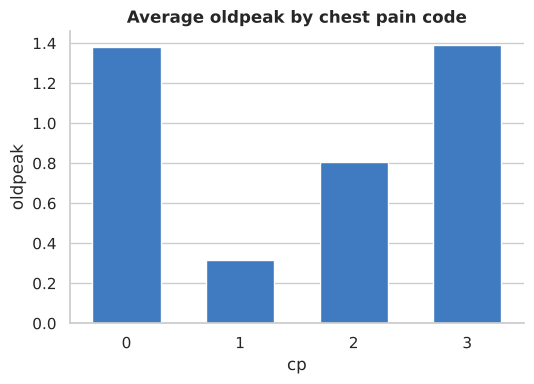

In [35]:
display(df.groupby("cp")["oldpeak"].agg(["count", "mean", "median"]).round(2))
groups = [g.oldpeak.values for _, g in df.groupby("cp")]
print(f"Kruskal-Wallis across chest pain types: {p_text(stats.kruskal(*groups)[1])}")

fig, ax = plt.subplots(figsize=(5.5, 4))
sns.barplot(data=df, x="cp", y="oldpeak", ax=ax, color=BLUE, errorbar=None, width=0.6)
ax.set_title("Average oldpeak by chest pain code"); ax.set_xlabel("cp")
save("10_m7_oldpeak_by_cp")

### M8. Thalassemia (`thal`) among patients with heart disease
*Hint: `pd.crosstab(data['thal'], data['target']).plot(kind='bar', stacked=True)`. Why it matters: may point to patients who need genetic counseling or specialised care.*

,patients,with_disease,rate
thal,,,
1,18,12,66.7%
2,167,37,22.2%
3,117,89,76.1%


Chi-square: p < 0.001

Share of all disease cases by thal code:
thal
1     8.7
2    26.8
3    64.5


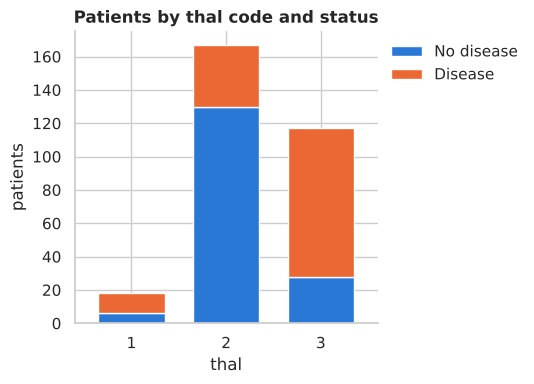

In [36]:
display(rate_table("thal"))
print(f"Chi-square: {p_text(chi2_p('thal'))}")
print("\nShare of all disease cases by thal code:")
print((df[df.disease == 1].thal.value_counts(normalize=True).sort_index() * 100).round(1).to_string())

fig, ax = plt.subplots(figsize=(5.5, 4)); stacked("thal", ax)
ax.set_title("Patients by thal code and status")
save("11_m8_thal_vs_disease")

**Label warning:** the dictionary says `thal` 1 = normal, 2 = fixed defect, 3 = reversible defect. But code 2 is the most common *and* has the lowest disease rate, which is how a "normal" code would behave. The labels in the brief seem to be shifted. We therefore refer to `thal` by code only. Check with the data owner before naming these categories in a report.

### M9. Most common risk-factor combinations among patients with disease
*Hint: `data[data.target==1].groupby(['cp','fbs','exang','thal']).size()`. Why it matters: reveals typical patient profiles for targeted programs.*

In [37]:
combo_cols = ["cp", "fbs", "exang", "thal"]
combo = (df.groupby(combo_cols)["disease"].agg(patients="size", with_disease="sum", disease_rate="mean")
           .reset_index().sort_values("with_disease", ascending=False))
combo["disease_rate"] = (combo["disease_rate"] * 100).round(0).astype(int).astype(str) + "%"
combo["share_of_all_disease_cases"] = (combo["with_disease"] / df.disease.sum() * 100).round(1)
combo.head(8).reset_index(drop=True)

,cp,fbs,exang,thal,patients,with_disease,disease_rate,share_of_all_disease_cases
0,0,0,1,3,43,40,93%,29.0
1,0,0,0,3,22,19,86%,13.8
2,0,0,1,2,20,14,70%,10.1
3,0,1,1,3,9,9,100%,6.5
4,2,0,0,3,14,8,57%,5.8
5,0,0,0,2,30,7,23%,5.1
6,2,0,0,2,47,5,11%,3.6
7,0,0,1,1,5,4,80%,2.9


A count on its own can mislead (a combination may be common simply because many people have it), so the table also shows the disease rate inside each combination.

### M10. Compare clinical measurements: disease vs no disease
*Hint: `describe()` for each group, then a pair plot. Why it matters: shows which measurements separate the two groups.*

In [38]:
display(df.groupby("status")[NUM].agg(["mean", "median"]).round(1).T)

rows = []
for c in NUM:
    a, b = df.loc[df.disease == 1, c], df.loc[df.disease == 0, c]
    rows.append({"measurement": c, "mean (disease)": a.mean(), "mean (no disease)": b.mean(),
                 "effect size (Cohen d)": cohens_d(a, b), "p-value": stats.mannwhitneyu(a, b)[1]})
effect = pd.DataFrame(rows).set_index("measurement").round(3).sort_values("effect size (Cohen d)", key=abs, ascending=False)
effect

status           Disease  No disease
age      mean       56.6        52.6
         median     58.0        52.0
trestbps mean      134.4       129.2
         median    130.0       130.0
chol     mean      251.1       242.6
         median    249.0       234.5
thalach  mean      139.1       158.4
         median    142.0       161.0
oldpeak  mean        1.6         0.6
         median      1.4         0.2

,mean (disease),mean (no disease),effect size (Cohen d),p-value
measurement,,,,
oldpeak,1.586,0.587,0.951,0.000
thalach,139.101,158.378,-0.926,0.000
age,56.601,52.585,0.454,0.000
trestbps,134.399,129.250,0.296,0.032
chol,251.087,242.640,0.163,0.042


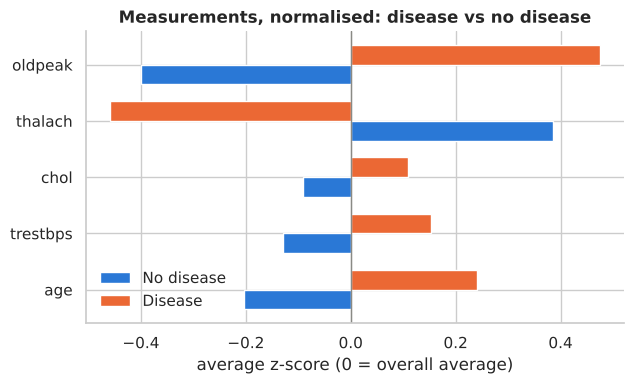

In [39]:
# side by side on one scale: average z-score for each group
z = df_scaled.assign(status=df.status).groupby("status")[NUM].mean().loc[STATUS_ORDER].T
ax = z.plot(kind="barh", color=[BLUE, ORANGE], figsize=(6.5, 4), width=0.7, edgecolor="white")
ax.axvline(0, color=GREY, lw=1); ax.set_xlabel("average z-score (0 = overall average)"); ax.set_ylabel("")
ax.legend(frameon=False, title=""); ax.set_title("Measurements, normalised: disease vs no disease")
save("12_m10_normalised_comparison")

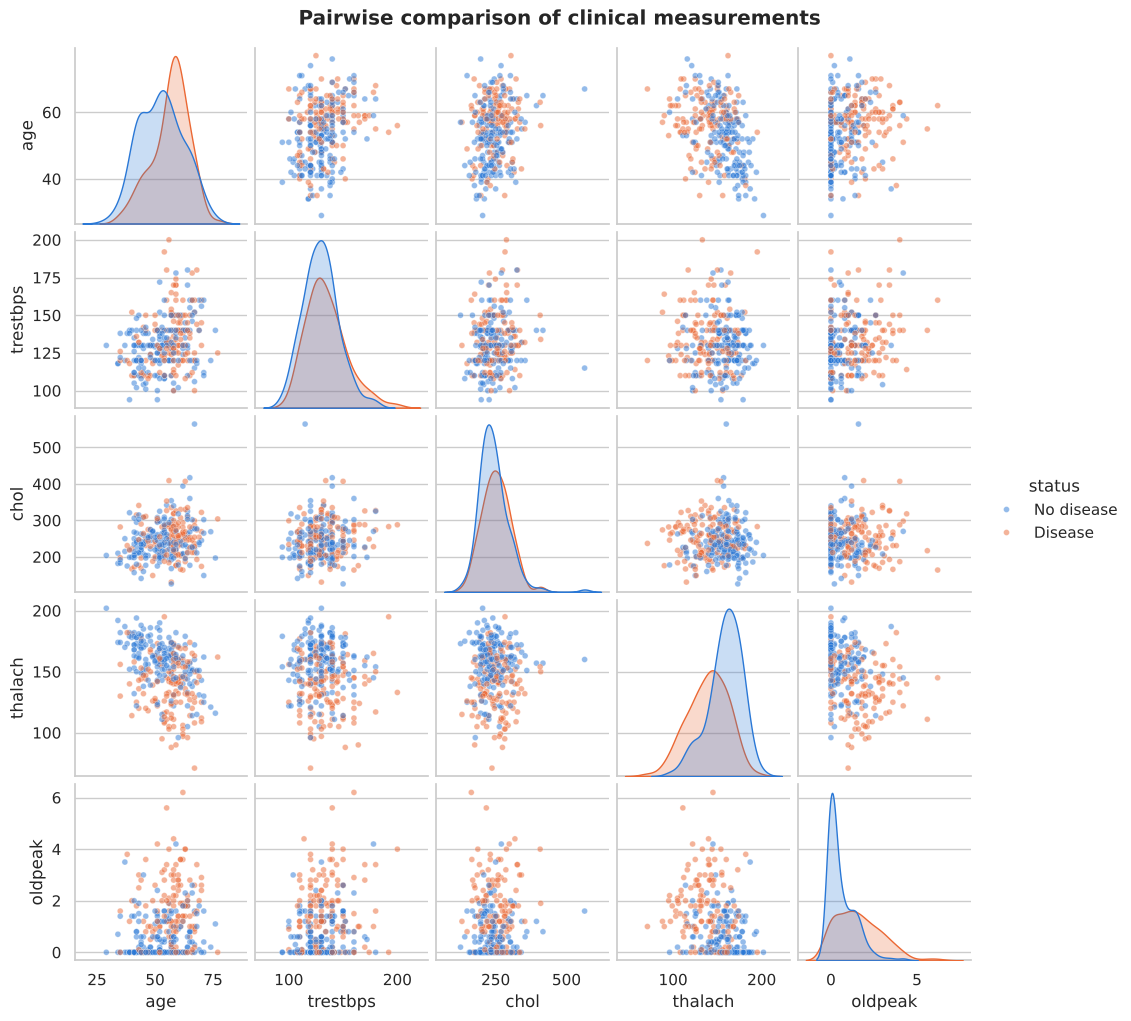

In [40]:
g = sns.pairplot(df, vars=["age", "trestbps", "chol", "thalach", "oldpeak"], hue="status", hue_order=STATUS_ORDER,
                 palette=PAL, plot_kws={"alpha": 0.5, "s": 18}, diag_kind="kde", height=2)
g.fig.suptitle("Pairwise comparison of clinical measurements", y=1.02, fontweight="bold")
g.savefig(FIG_DIR / "13_m10_pairplot.png", dpi=120, bbox_inches="tight")
plt.show()

## 6. Advanced questions

### A1. Combined effect of age, cholesterol and blood pressure
*Hint: `sns.pairplot(data, hue='target', vars=['age','chol','trestbps'])`. Why it matters: risk is rarely from one factor alone.*

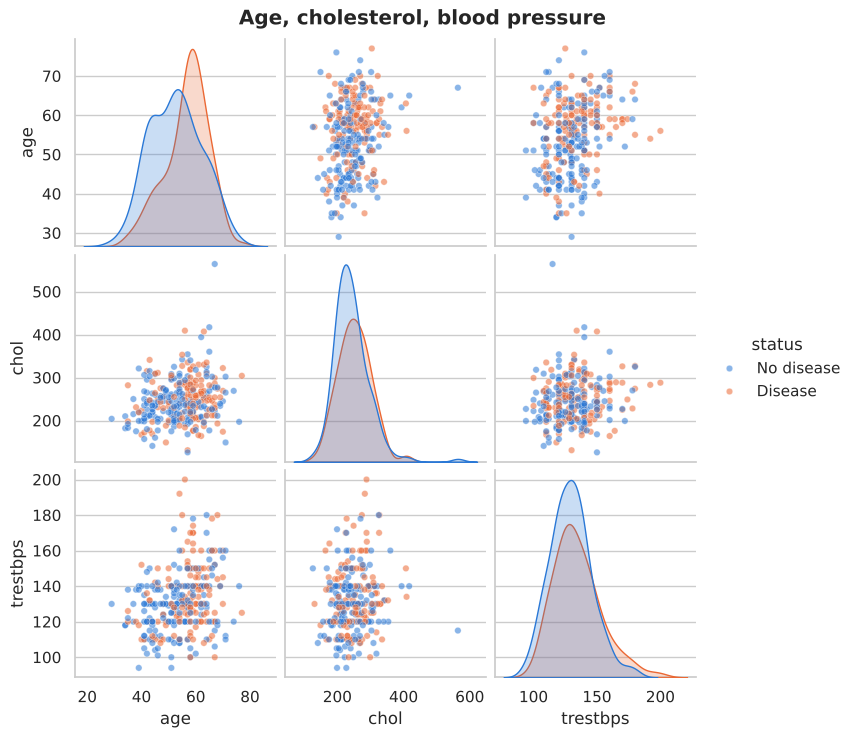

In [41]:
g = sns.pairplot(df, vars=["age", "chol", "trestbps"], hue="status", hue_order=STATUS_ORDER, palette=PAL,
                 plot_kws={"alpha": 0.55, "s": 22}, diag_kind="kde", height=2.4)
g.fig.suptitle("Age, cholesterol, blood pressure", y=1.02, fontweight="bold")
g.savefig(FIG_DIR / "14_a1_pairplot_age_chol_bp.png", dpi=120, bbox_inches="tight")
plt.show()

In [42]:
# Count how many of the three 'elevated' flags a patient has and compare disease rates
three = pd.DataFrame({"age >= 55": df.age >= 55, "chol >= 240": df.chol >= 240, "BP >= 140": df.trestbps >= 140}).astype(int)
df["n_flags_3"] = three.sum(axis=1)
t = df.groupby("n_flags_3")["disease"].agg(patients="size", rate="mean")
t["rate"] = (t["rate"] * 100).round(1)
display(t)

print("Disease rate by single flag (flag present vs absent):")
for c in three.columns:
    print(f"  {c:12s} present: {df.disease[three[c] == 1].mean():.0%}   absent: {df.disease[three[c] == 0].mean():.0%}")

,patients,rate
n_flags_3,,
0,65,26.2
1,103,39.8
2,94,58.5
3,40,62.5


Disease rate by single flag (flag present vs absent):
  age >= 55    present: 59%   absent: 31%
  chol >= 240  present: 51%   absent: 40%
  BP >= 140    present: 55%   absent: 41%


Read the two parts together: the pair plot shows heavy overlap between the groups (these three measures alone do not separate patients well), and the flag count shows how much, or how little, stacking them adds.

### A2. Which variable has the strongest correlation with heart disease?
*Hint: `data.corr()['target'].sort_values()`. Why it matters: focus prevention on the strongest signals.*

cp         -0.43
thalach    -0.42
slope      -0.34
restecg    -0.13
fbs         0.03
chol        0.08
trestbps    0.15
age         0.22
sex         0.28
thal        0.36
oldpeak     0.43
exang       0.44
ca          0.46


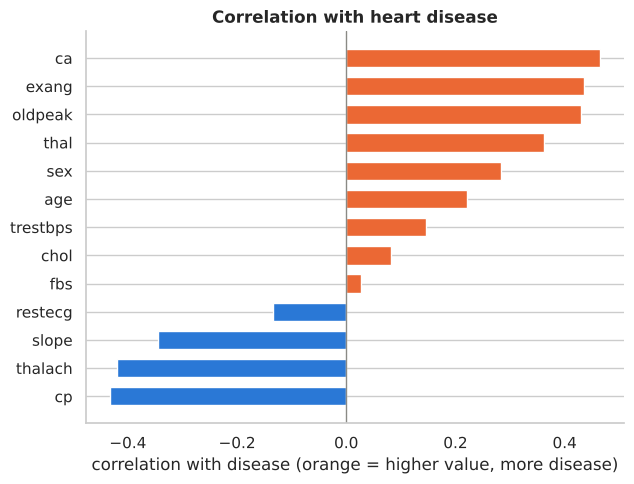

In [43]:
corr = df[NUM + CAT + ["disease"]].corr()["disease"].drop("disease").sort_values()
print(corr.round(2).to_string())

fig, ax = plt.subplots(figsize=(6.5, 5))
colors = [ORANGE if v > 0 else BLUE for v in corr.values]
ax.barh(corr.index, corr.values, color=colors, height=0.65)
ax.axvline(0, color=GREY, lw=1)
ax.set_xlabel("correlation with disease (orange = higher value, more disease)")
ax.set_title("Correlation with heart disease")
save("15_a2_correlation_with_disease")

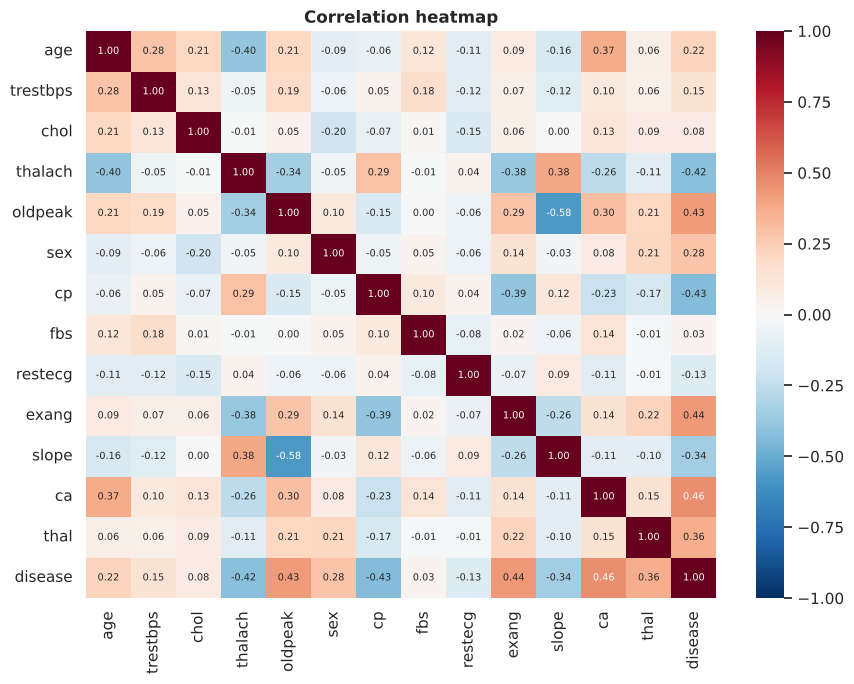

In [44]:
plt.figure(figsize=(9, 7))
sns.heatmap(df[NUM + CAT + ["disease"]].corr(), annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1, annot_kws={"size": 7})
plt.title("Correlation heatmap")
save("16_a2_correlation_heatmap")

In [45]:
top_meas = corr[NUM].abs().idxmax()
top_all = corr.abs().idxmax()
print(f"Strongest among the 5 clinical measurements: {top_meas} (r = {corr[top_meas]:.2f})")
print(f"Strongest overall                          : {top_all} (r = {corr[top_all]:.2f})")

Strongest among the 5 clinical measurements: oldpeak (r = 0.43)
Strongest overall                          : ca (r = 0.46)


Note: `cp`, `slope`, `ca`, `thal` are codes, so their correlations are only rough guides; the category tables in 3.7 and Section 5 are more reliable for those.

### A3. Logistic regression to predict heart disease
*Hint: `LogisticRegression` from sklearn. Why it matters: a model can flag at-risk patients early and rank the factors.*

Setup: capped data (the cap limits were worked out on all 302 patients, a small shortcut), numbers scaled and categories one-hot encoded inside a pipeline, 75/25 stratified split, plus 5x5 repeated cross-validation because 302 patients is a small test set.

In [46]:
FEAT_NUM = ["age", "trestbps", "chol", "thalach", "oldpeak", "ca"]
FEAT_CAT = ["sex", "cp", "fbs", "restecg", "exang", "slope", "thal"]

def make_model():
    pre = ColumnTransformer([("num", StandardScaler(), FEAT_NUM),
                             ("cat", OneHotEncoder(drop="first"), FEAT_CAT)])
    return Pipeline([("prep", pre), ("clf", LogisticRegression(max_iter=1000))])

X, y = df_capped[FEAT_NUM + FEAT_CAT], df_capped["disease"]
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.25, stratify=y, random_state=RANDOM_STATE)

model = make_model().fit(X_tr, y_tr)
pred, prob = model.predict(X_te), model.predict_proba(X_te)[:, 1]

results = pd.Series({
    "accuracy": accuracy_score(y_te, pred), "precision": precision_score(y_te, pred),
    "recall": recall_score(y_te, pred), "F1": f1_score(y_te, pred), "ROC-AUC": roc_auc_score(y_te, prob)}).round(3)
print("Test-set results (n =", len(y_te), ")"); print(results.to_string())
print(f"\nBaseline (always guess the majority class): {max(y_te.mean(), 1 - y_te.mean()):.3f}")

cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=5, random_state=RANDOM_STATE)
cv_acc = cross_val_score(make_model(), X, y, cv=cv, scoring="accuracy")
cv_auc = cross_val_score(make_model(), X, y, cv=cv, scoring="roc_auc")
print(f"\n5x5 cross-validation: accuracy {cv_acc.mean():.3f} (+/- {cv_acc.std():.3f}) | ROC-AUC {cv_auc.mean():.3f} (+/- {cv_auc.std():.3f})")

Test-set results (n = 76 )
accuracy     0.829
precision    0.844
recall       0.771
F1           0.806
ROC-AUC      0.899

Baseline (always guess the majority class): 0.539



5x5 cross-validation: accuracy 0.844 (+/- 0.036) | ROC-AUC 0.913 (+/- 0.024)


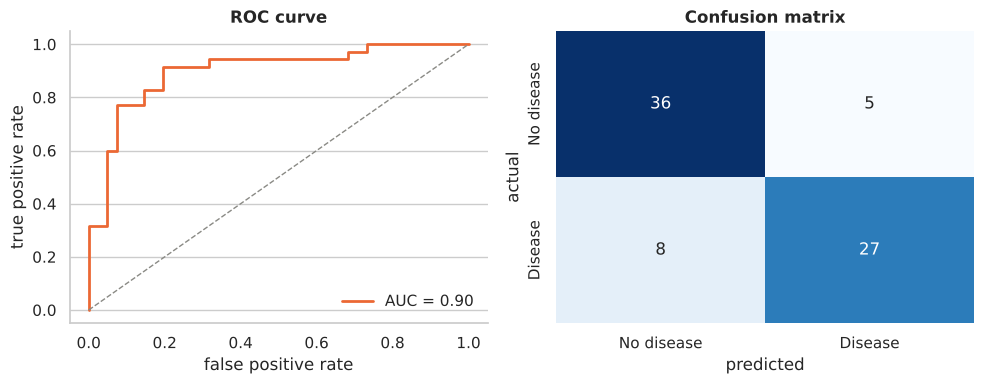

In [47]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
fpr, tpr, _ = roc_curve(y_te, prob)
axes[0].plot(fpr, tpr, color=ORANGE, lw=2, label=f"AUC = {roc_auc_score(y_te, prob):.2f}")
axes[0].plot([0, 1], [0, 1], color=GREY, ls="--", lw=1)
axes[0].set(xlabel="false positive rate", ylabel="true positive rate", title="ROC curve"); axes[0].legend(frameon=False)

cm = confusion_matrix(y_te, pred)
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=axes[1],
            xticklabels=["No disease", "Disease"], yticklabels=["No disease", "Disease"])
axes[1].set(xlabel="predicted", ylabel="actual", title="Confusion matrix")
save("17_a3_model_roc_confusion")

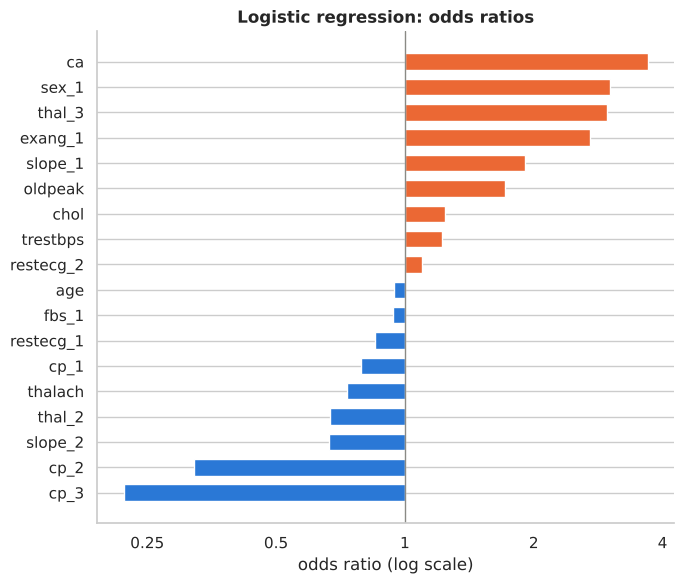

,feature,odds_ratio
0,ca,3.70
1,sex_1,3.01
2,thal_3,2.97
3,exang_1,2.71
4,slope_1,1.91
5,oldpeak,1.71
6,chol,1.24
7,trestbps,1.22
8,restecg_2,1.10
9,age,0.95


In [48]:
# Which factors matter? Odds ratios from the fitted model (>1 raises risk, <1 lowers it)
names = model.named_steps["prep"].get_feature_names_out()
names = [n.replace("num__", "").replace("cat__", "") for n in names]
coefs = model.named_steps["clf"].coef_[0]
odds = pd.DataFrame({"feature": names, "odds_ratio": np.exp(coefs)}).sort_values("odds_ratio")

fig, ax = plt.subplots(figsize=(7, 6))
ax.barh(odds.feature, odds.odds_ratio - 1, left=1, color=[ORANGE if v > 1 else BLUE for v in odds.odds_ratio], height=0.65)
ax.axvline(1, color=GREY, lw=1); ax.set_xscale("log"); ax.set_xticks([0.25, 0.5, 1, 2, 4]); ax.set_xticklabels(["0.25", "0.5", "1", "2", "4"]); ax.minorticks_off()
ax.set_xlabel("odds ratio (log scale)"); ax.set_title("Logistic regression: odds ratios")
save("18_a3_odds_ratios")
display(odds.sort_values("odds_ratio", ascending=False).round(2).reset_index(drop=True))

How to read it: numeric features are standardised, so their odds ratio is *per one standard deviation increase*. Category features (e.g. `cp_1`) are compared against the first category of that column (the one left out). Odds ratios from a small dataset are rough, not exact.

In [49]:
# Why duplicates matter: same split on the raw file (1,025 rows) vs the cleaned data (302 rows)
from sklearn.ensemble import RandomForestClassifier

def acc_on(Xa, ya, clf):
    a, b, c, d = train_test_split(Xa, ya, test_size=0.25, stratify=ya, random_state=RANDOM_STATE)
    return accuracy_score(d, clf.fit(a, c).predict(b))

Xr, yr = raw[FEAT_NUM + FEAT_CAT], raw["disease"]
rf = lambda: RandomForestClassifier(n_estimators=200, random_state=RANDOM_STATE)
print(f"Logistic regression | raw file: {acc_on(Xr, yr, make_model()):.3f} | cleaned: {acc_on(X, y, make_model()):.3f}")
print(f"Random forest       | raw file: {acc_on(Xr, yr, rf()):.3f} | cleaned: {acc_on(X, y, rf()):.3f}")

Logistic regression | raw file: 0.829 | cleaned: 0.829


Random forest       | raw file: 0.977 | cleaned: 0.842


With raw duplicates, the same patient can sit in both the training and the test set. A simple model like logistic regression barely cares, but a flexible model (random forest) can memorise patients and looks far better than it really is. The cleaned-data score is the honest one. This is a good reason to remove duplicates before any modeling.

### A4. How does the ST-segment `slope` vary with chest pain type?
*Hint: `groupby('cp')['slope'].value_counts().unstack().plot(kind='bar', stacked=True)`. Why it matters: links symptoms with ECG patterns.*

slope,0,1,2
cp,,,
0,11,84,48
1,2,12,36
2,5,33,48
3,3,11,9


Chi-square: p < 0.001 | Cramer's V = 0.21 (0 = no link, 1 = perfect link)


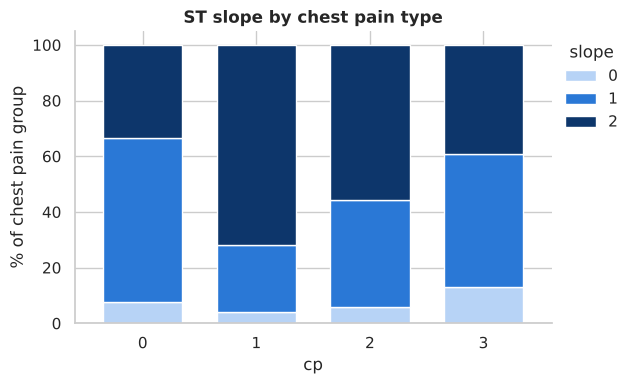

In [50]:
ct = pd.crosstab(df.cp, df.slope)
display(ct)
chi2, p, _, _ = stats.chi2_contingency(ct)
v = np.sqrt(chi2 / (ct.values.sum() * (min(ct.shape) - 1)))
print(f"Chi-square: {p_text(p)} | Cramer's V = {v:.2f} (0 = no link, 1 = perfect link)")

ax = (ct.div(ct.sum(axis=1), axis=0) * 100).plot(kind="bar", stacked=True, color=BLUES4[:ct.shape[1]] if ct.shape[1] == 4 else ["#b7d3f6", "#2a78d6", "#0d366b"], figsize=(6.5, 4), edgecolor="white", width=0.7)
ax.set_ylabel("% of chest pain group"); ax.set_xlabel("cp"); ax.tick_params(axis="x", rotation=0)
ax.legend(title="slope", frameon=False, bbox_to_anchor=(1, 1)); ax.set_title("ST slope by chest pain type")
save("19_a4_slope_by_cp")

### A5. "Survival rates" of patients with different thalassemia types over time
*Hint in the brief: `sns.lineplot(x='age', y='thal', hue='target')`.*

**This question cannot be answered as written.** The dataset is a one-time snapshot: there is no follow-up date, no death or survival column, and no time axis. A lineplot of `thal` (a category code) against `age` would not show survival; it would plot an average of category codes. What the data *can* show is **how disease prevalence changes with age within each `thal` code**, so that is what we do.

age_band,n: under 50,n: 50-59,n: 60+
thal,,,
1,3,10,5
2,61,59,47
3,23,56,38


age_band,% disease: under 50,% disease: 50-59,% disease: 60+
thal,,,
1,67.0,70.0,60.0
2,10.0,22.0,38.0
3,78.0,71.0,82.0


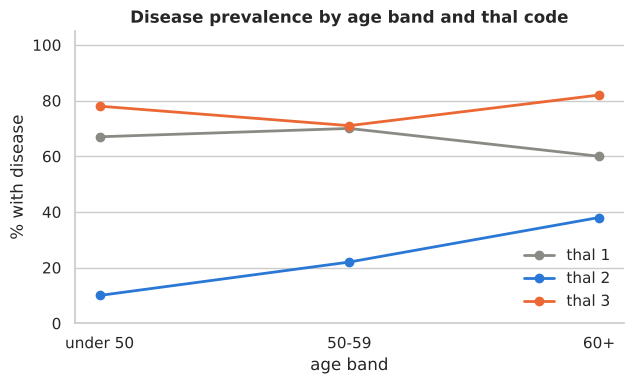

In [51]:
df["age_band"] = pd.cut(df.age, bins=[0, 49, 59, 120], labels=["under 50", "50-59", "60+"])
prev = df.groupby(["thal", "age_band"])["disease"].agg(patients="size", rate="mean").reset_index()
prev["rate"] = (prev["rate"] * 100).round(0)
display(prev.pivot(index="thal", columns="age_band", values="patients").add_prefix("n: "))
display(prev.pivot(index="thal", columns="age_band", values="rate").add_prefix("% disease: "))

fig, ax = plt.subplots(figsize=(6.5, 4))
for code_, color in zip([1, 2, 3], [GREY, BLUE, ORANGE]):
    s = prev[prev.thal == code_]
    ax.plot(s.age_band.astype(str), s.rate, marker="o", color=color, lw=2, label=f"thal {code_}")
ax.set_ylim(0, 105); ax.set_ylabel("% with disease"); ax.set_xlabel("age band")
ax.set_title("Disease prevalence by age band and thal code"); ax.legend(frameon=False)
save("20_a5_prevalence_by_thal_age")

Some cells have very few patients (see the patient counts above), so lines for thal 1 especially are unstable. A real survival analysis would need follow-up data.

**Ethics and privacy (from the brief):** patient data needs privacy protection, and any model should be validated by clinicians before real use. Predictions support, not replace, a doctor's judgment.

## 7. High-risk patient profile

A simple, explainable **red-flag score**: one point for each risk marker that showed up strongly in the analysis. Easy to explain to a clinician, unlike a model's raw coefficients.

In [52]:
flags = pd.DataFrame({
    "male": df.sex == 1,
    "chest pain code 0": df.cp == 0,
    "exercise angina": df.exang == 1,
    "oldpeak >= 1": df.oldpeak >= 1,
    "1+ vessels (ca)": df.ca >= 1,
    "thal code not 2": df.thal != 2,
    "max HR < 140": df.thalach < 140,
    "age >= 55": df.age >= 55,
}).astype(int)
df["risk_score"] = flags.sum(axis=1)

by_score = df.groupby("risk_score")["disease"].agg(patients="size", rate="mean")
by_score["rate"] = (by_score["rate"] * 100).round(1)
display(by_score)
print("Flag prevalence:"); print((flags.mean() * 100).round(0).astype(int).astype(str).add("%").to_string())

,patients,rate
risk_score,,
0,16,0.0
1,44,2.3
2,52,9.6
3,51,39.2
4,30,43.3
5,40,82.5
6,28,96.4
7,30,93.3
8,11,100.0


Flag prevalence:
male                 68%
chest pain code 0    47%
exercise angina      33%
oldpeak >= 1         45%
1+ vessels (ca)      41%
thal code not 2      45%
max HR < 140         28%
age >= 55            53%


,patients,with_disease,rate
risk_band,,,
Low (0-2),112,6,5.4
Medium (3-4),81,33,40.7
High (5+),109,99,90.8


AUC of the simple score on this data: 0.91 (optimistic: the flags were chosen using this same data)


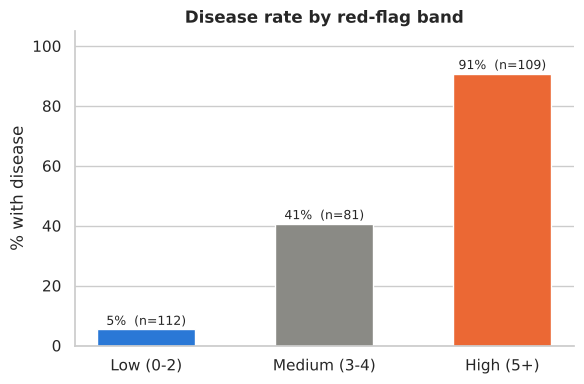

In [53]:
df["risk_band"] = pd.cut(df.risk_score, bins=[-1, 2, 4, 8], labels=["Low (0-2)", "Medium (3-4)", "High (5+)"])
band = df.groupby("risk_band", observed=True)["disease"].agg(patients="size", with_disease="sum", rate="mean")
band["rate"] = (band["rate"] * 100).round(1)
display(band)
print(f"AUC of the simple score on this data: {roc_auc_score(df.disease, df.risk_score):.2f} "
      "(optimistic: the flags were chosen using this same data)")

fig, ax = plt.subplots(figsize=(6, 4))
ax.bar(band.index.astype(str), band.rate, color=[BLUE, GREY, ORANGE], width=0.55)
for i, (r, n) in enumerate(zip(band.rate, band.patients)):
    ax.text(i, r + 1.5, f"{r:.0f}%  (n={n})", ha="center", fontsize=9)
ax.set_ylim(0, 105); ax.set_ylabel("% with disease"); ax.set_title("Disease rate by red-flag band")
save("21_risk_band_disease_rate")

In [54]:
# Who is in the high-risk band vs the low-risk band?
prof = df.groupby("risk_band", observed=True).agg(
    patients=("age", "size"), avg_age=("age", "mean"), pct_male=("sex", lambda s: s.mean() * 100),
    avg_chol=("chol", "mean"), avg_bp=("trestbps", "mean"), avg_max_hr=("thalach", "mean"),
    avg_oldpeak=("oldpeak", "mean"), pct_angina=("exang", lambda s: s.mean() * 100),
    avg_vessels=("ca", "mean")).round(1)
prof.T

risk_band,Low (0-2),Medium (3-4),High (5+)
patients,112.0,81.0,109.0
avg_age,49.6,55.8,58.3
pct_male,48.2,74.1,84.4
avg_chol,243.5,243.8,251.6
avg_bp,128.2,132.2,134.6
avg_max_hr,163.8,152.8,132.6
avg_oldpeak,0.4,0.9,1.8
pct_angina,5.4,23.5,67.9
avg_vessels,0.2,0.4,1.3


In [55]:
# Typical profile of a patient WITH disease vs WITHOUT, in plain numbers
typ = df.groupby("status").agg(avg_age=("age", "mean"), pct_male=("sex", lambda s: s.mean() * 100),
                               avg_chol=("chol", "mean"), avg_bp=("trestbps", "mean"),
                               avg_max_hr=("thalach", "mean"), avg_oldpeak=("oldpeak", "mean"),
                               pct_angina=("exang", lambda s: s.mean() * 100),
                               pct_cp0=("cp", lambda s: (s == 0).mean() * 100),
                               pct_1plus_vessels=("ca", lambda s: (s >= 1).mean() * 100)).round(1).loc[STATUS_ORDER]
typ.T

status,No disease,Disease
avg_age,52.6,56.6
pct_male,56.1,82.6
avg_chol,242.6,251.1
avg_bp,129.2,134.4
avg_max_hr,158.4,139.1
avg_oldpeak,0.6,1.6
pct_angina,14.0,55.1
pct_cp0,23.8,75.4
pct_1plus_vessels,18.9,66.7


## 8. Summary, recommendations, further research

In [56]:
print("KEY NUMBERS")
print(f"- Patients analysed: {len(df)} (raw file had {len(raw)} rows, {raw.duplicated().sum()} duplicates removed)")
print(f"- Disease prevalence: {df.disease.mean():.1%}")
print(f"- Average age {df.age.mean():.1f}; {df.sex.mean():.0%} male")
print(f"- Disease rate: men {df[df.sex==1].disease.mean():.0%} vs women {df[df.sex==0].disease.mean():.0%}")
print(f"- Disease rate with exercise angina {df[df.exang==1].disease.mean():.0%} vs without {df[df.exang==0].disease.mean():.0%}")
print(f"- Disease rate with 0 vessels {df[df.ca==0].disease.mean():.0%} vs 1+ vessels {df[df.ca>=1].disease.mean():.0%}")
print(f"- Model: test accuracy {accuracy_score(y_te, pred):.2f}, ROC-AUC {roc_auc_score(y_te, prob):.2f}; CV accuracy {cv_acc.mean():.2f}")
print(f"- Red-flag bands: low {band.rate.iloc[0]:.0f}%, medium {band.rate.iloc[1]:.0f}%, high {band.rate.iloc[2]:.0f}%")
print(f"- Cholesterol, fasting sugar and resting BP: weak links (r = {corr['chol']:.2f}, {corr['fbs']:.2f}, {corr['trestbps']:.2f})")

KEY NUMBERS
- Patients analysed: 302 (raw file had 1025 rows, 723 duplicates removed)
- Disease prevalence: 45.7%
- Average age 54.4; 68% male
- Disease rate: men 55% vs women 25%
- Disease rate with exercise angina 77% vs without 31%
- Disease rate with 0 vessels 26% vs 1+ vessels 75%
- Model: test accuracy 0.83, ROC-AUC 0.90; CV accuracy 0.84
- Red-flag bands: low 5%, medium 41%, high 91%
- Cholesterol, fasting sugar and resting BP: weak links (r = 0.08, 0.03, 0.15)


### Recommended actions (for discussion with clinicians)
1. **Screen by symptoms *and* test results, not symptoms alone.** Chest pain code 0 had the highest disease rate in this data, so patients without classic symptoms should not be waved through. Use exercise test results (`oldpeak`, `exang`, `thalach`) and vessel findings (`ca`) in triage.
2. **Prioritise patients with several red flags.** The red-flag score gives a simple way to sort a waiting list: more flags, faster follow-up.
3. **Do not rely on cholesterol, blood pressure or fasting sugar alone as screening tools.** In this data they separate patients weakly. They still matter for long-term health, so keep them as routine checks and lifestyle advice (diet, activity, blood-sugar control) rather than as the sole risk filter.
4. **Exercise programs:** patients with exercise-induced angina reach a lower peak heart rate, so supervised, gradually progressed plans make sense for them.
5. **Men and older patients** form the larger share of the disease group here, so targeted outreach and earlier check-ups for these groups are reasonable.

### Areas for further research
- Why are disease rates so different between men and women in this data, and is it sampling or something real?
- Why does a symptom-free (code 0) chest pain presentation go with a higher disease rate? Confirm what the codes stand for.
- Confirm the `target` direction and `thal` labels with the research institute; get a larger dataset with real patient IDs (no duplicates) and follow-up dates, so survival analysis becomes possible.
- Add lifestyle data (smoking, weight, activity, family history) which this dataset lacks.

### Limitations
- Only 302 unique patients from one source, so results are indicative, not final.
- Single snapshot: shows association, not cause.
- Several code meanings (`cp`, `restecg`, `slope`, `thal`) are not defined in the brief.
- The red-flag score was built and checked on the same data, so its accuracy is optimistic.
- Not medical advice.